# 07 · Two-stage stacked ensemble (X4), final model and submission

Stage 1 is a set of diverse base models trained on the train part: word TF-IDF (B0), per-language (X1), per-domain (X2g), the label cascade (X5), character n-grams (X6), the sentence model (X7), the encoder (E1, with its window statistics), the token-level encoder (E2, with its per-text token summaries) and the LM-feature classifier (X3). Stage 2 is a gradient-boosting stacker per language whose inputs are their validation/test outputs, the given `domain` column (present in test) and text statistics. Raw LM features are switched off (`lm_features: false`); X3's scores carry the same signal. The stage-1 domain classifier is not used: X2 vs X2g in `06` shows that predicting the domain only matches the given column.

The stacker only sees validation rows: it is scored with out-of-fold predictions from a 5-fold `StratifiedGroupKFold` over the validation split (groups from `02_split`), so it is never evaluated on rows it was fitted on; for the test set it is refit on all validation rows. Members missing on disk are skipped. X4b adds per-language class offsets to the stacker's log-probabilities, tuned for macro-F1; the offsets for each validation fold come from the other folds.

The final model is the one with the highest validation macro-F1 in the experiment log.

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

from hw3.config import ROOT, art, load_config

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 200, "display.max_columns", 40)
FIG = ROOT / "images"

from hw3 import ensemble
from hw3.runs import compare, error_overlap, experiment_log, report
from hw3.submission import save_submission, select_final

In [2]:
Xv, oof = ensemble.run_ensemble(load_config("ensemble"))
meta = json.loads(art("runs", "X4.json").read_text())
meta["members"], Xv.shape, json.loads(art("runs", "X4b.json").read_text())["offsets"]

(['B0', 'X1', 'X2g', 'X5', 'X6', 'X7', 'E1', 'E2', 'X3'],
 (27234, 83),
 {'de-DE': {'human': 0.0, 'ai': -1.0, 'fusion': 0.6},
  'en-EN': {'human': 0.0, 'ai': 0.3, 'fusion': -0.05}})

,precision,recall,f1,support
human,0.9243,0.9678,0.9455,6672
ai,0.9978,0.9972,0.9975,12196
fusion,0.9718,0.9362,0.9537,8366


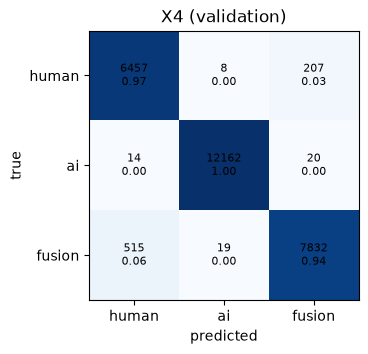

In [3]:
rep = report("X4")
rep["figure"].savefig(FIG / "confusion_X4.png", dpi=150, bbox_inches="tight")
rep["per_class"]

In [4]:
compare(["B0", "X1", "X2g", "X5", "X6", "X7", "E1", "E2", "X3", "X4", "X4b"])

B0      X1     X2g      X5      X6      X7      E1      E2      X3      X4     X4b
all   all                     0.8657  0.8693  0.8665  0.8833  0.8080  0.9077  0.9304  0.9329  0.6818  0.9656  0.9655
de-DE bundestag               0.9072  0.9098  0.9051  0.9201  0.7714  0.9322  0.9244  0.9444  0.7265  0.9778  0.9773
      gutenberg               0.4953  0.5000  0.4953  0.5000  0.5000  0.4804  0.6000  0.6000  0.5143  0.6000  0.6000
en-EN arxiv_papers            0.8494  0.8627  0.8786  0.9060  0.6167  0.9102  0.6278  0.8047  0.5705  0.9667  0.9667
      blog_authorship_corpus  0.7376  0.7459  0.7380  0.7563  0.7604  0.7732  0.8772  0.8902  0.5662  0.9051  0.9041
      cnn_news                0.8272  0.8375  0.8259  0.8683  0.8495  0.9120  0.9765  0.9566  0.6895  0.9925  0.9925
      euro_court_cases        0.8991  0.8984  0.9039  0.9179  0.7751  0.9447  0.9005  0.9355  0.6080  0.9696  0.9716
      gutenberg               0.7373  0.7417  0.6912  0.8429  0.6353  0.9389  0.8613  0.8767  0.5942  0.9825  0.9825
      house_of_commons        0.8725  0.8725  0.8870  0.8947  0.8284  0.9424  0.9261  0.9488  0.6381  0.9760  0.9769
      student_essays          0.9097  0.9095  0.9061  0.9159  0.8403  0.9326  0.9604  0.9277  0.7236  0.9684  0.9676

Error overlap of the members on the validation split: an ensemble gains where one member is wrong and another is right (`only_one_wrong`), not where both are wrong.

In [5]:
error_overlap(meta["members"])

n  both_wrong  only_one_wrong
B0  X1   27234      0.0899          0.0461
    X2g  27234      0.0858          0.0566
    X5   27234      0.0827          0.0476
    X6   27234      0.0615          0.1532
    X7   27234      0.0447          0.1047
    E1   27234      0.0226          0.1273
    E2   27234      0.0246          0.1216
    X3   27234      0.0649          0.2721
X1  X2g  27234      0.0794          0.0662
    X5   27234      0.0750          0.0596
    X6   27234      0.0641          0.1449
    X7   27234      0.0442          0.1023
    E1   27234      0.0230          0.1232
    E2   27234      0.0239          0.1197
    X3   27234      0.0651          0.2684
X2g X5   27234      0.0723          0.0674
    X6   27234      0.0594          0.1567
    X7   27234      0.0430          0.1073
    E1   27234      0.0219          0.1279
    E2   27234      0.0236          0.1227
    X3   27234      0.0644          0.2722
X5  X6   27234      0.0552          0.1497
    X7   27234      0.0457          0.0865
    E1   27234      0.0227          0.1109
    E2   27234      0.0252          0.1042
    X3   27234      0.0570          0.2718
X6  X7   27234      0.0405          0.1602
    E1   27234      0.0295          0.1606
    E2   27234      0.0270          0.1639
    X3   27234      0.0869          0.2753
X7  E1   27234      0.0186          0.1002
    E2   27234      0.0244          0.0870
    X3   27234      0.0453          0.2763
E1  E2   27234      0.0253          0.0636
    X3   27234      0.0312          0.2828
E2  X3   27234      0.0301          0.2833

## Final model selection

In [6]:
log = experiment_log()
best = select_final(log)
log

,id,reference,change,status,device,runtime_s,macro_f1,delta_vs_ref,f1_human,f1_ai,f1_fusion,notes
0,B0,NaN,reference model: global word TF-IDF (hashing) ...,ok,cpu,269.5,0.8657,NaN,0.8132,0.9779,0.8058,frozen before any experiment; every experiment...
1,E1,B0,fine-tuned XLM-R base; trains on one random 51...,ok,Tesla T4,8887.7,0.9304,0.0647,0.8878,0.9925,0.9110,max_chunks from EDA token counts: p99 of windo...
2,E2,E1,token-level XLM-R base: every token is tagged ...,ok,Tesla T4,8411.5,0.9329,0.0025,0.8963,0.9919,0.9107,targets lightly rewritten fusion: X4 calls 44%...
3,S1,B0,stacker trained on the train part: 5-fold grou...,ok,cpu,1201.4,0.9093,0.0436,0.8625,0.9932,0.8721,the X4 stacker only has 27k validation rows (5...
4,X1,B0,one model per language with its own feature/re...,ok,cpu,586.4,0.8693,0.0036,0.8190,0.9795,0.8095,motivated by EN/DE differences in EDA: German ...
5,X2,B0,two-stage: stage-1 domain classifier routes ea...,ok,cpu,277.6,0.8665,0.0008,0.8171,0.9780,0.8043,domains have very different class priors and s...
6,X2g,B0,two-stage with routing by the given domain col...,ok,cpu,NaN,0.8665,0.0008,0.8171,0.9778,0.8047,domains have very different class priors and s...
7,X3,B0,open-weight LM likelihood features (observer/p...,ok,cpu,6.9,0.6818,-0.1839,0.6136,0.8756,0.5561,segment spread targets fusion (partly rewritte...
8,X3_features,B0,open-weight LM likelihood features (observer/p...,ok,Tesla T4,8554.9,NaN,NaN,NaN,NaN,NaN,segment spread targets fusion (partly rewritte...
9,X4,B0,two-stage stacked ensemble: stage 1 diverse ba...,ok,cpu,113.5,0.9656,0.0999,0.9455,0.9975,0.9537,stacker is trained and scored with group k-fol...


In [7]:
best

id                                                             X4
reference                                                      B0
change          two-stage stacked ensemble: stage 1 diverse ba...
status                                                         ok
device                                                        cpu
runtime_s                                                   113.5
macro_f1                                                   0.9656
delta_vs_ref                                               0.0999
f1_human                                                   0.9455
f1_ai                                                      0.9975
f1_fusion                                                  0.9537
notes           stacker is trained and scored with group k-fol...
Name: 9, dtype: object

## Submission with automated checks

The checks run on the frame before writing and again on the file read back from disk; any failure raises and nothing is uploaded.

In [8]:
save_submission(best.id)

columns are exactly [id, label]         True
row count equals sample_submission      True
every id exactly once                   True
same id set as sample_submission        True
same row order as sample_submission     True
labels are lowercase human/ai/fusion    True
no missing values                       True
dtype: bool

Upload manually after the checks pass:

```bash
kaggle competitions submit -c ai-generated-text-detection-hw3-ucu-ai-2026 -f submission.csv -m "<model id>"
```